# Soal 2 - Data Analysis

> "Revenue is growing, but profit is falling. What is happening, what will happen next, and what should we do about it?"

Alur: **apa yang terjadi** (Task 1) -> **kenapa** (Task 2) -> **apa selanjutnya** (Task 3) -> **apa yang harus dilakukan** (Task 4) -> **ringkasan untuk Board** (Task 5).

### Dependencies

In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

pd.set_option('display.width', 200)
pd.set_option('display.max_columns', 30)
pd.options.display.float_format = '{:,.2f}'.format

### Import Data

In [9]:
path = '../Soal 1 - Data Inspection, Cleaning and Processing/output/df_clean.csv'

df = pd.read_csv(path, parse_dates=['order_date'])

df.shape

(7127, 29)

Dataset ini adalah **hasil cleaning Soal 1**, jadi masalah data sudah ditangani di sana. Ringkasannya:
- duplikat, test order, dan format label/tanggal sudah dibersihkan
- *unit_price*, *revenue*, *cost* yang tersimpan dalam ribuan rupiah (sejak Apr 2026) sudah dikali 1000
- *cost* yang kosong (mayoritas Networking) diisi estimasi dan diberi flag *cost_imputed*
- 8 baris Retail dengan qty 100-400 diberi flag *qty_outlier*

### Definisi dan asumsi untuk analisis ini

- **FY2025** = 1 Sep 2024 - 31 Aug 2025, **FY2026** = 1 Sep 2025 - 31 Aug 2026
- data berakhir 15 Sep 2026, jadi 1-15 Sep 2026 (FY2027) **tidak dipakai** dalam perbandingan FY
- *Cancelled* = order tidak terjadi, jadi net revenue = 0. *Returned* sudah bernilai negatif, jadi otomatis mengurangi
- 8 baris *qty_outlier* (Rp4,0 miliar) tidak dipakai karena tidak bisa diverifikasi (dampaknya dicek di bagian bawah)
- **Net revenue** = revenue setelah diskon, tanpa order Cancelled, dikurangi Return. **Gross profit** = net revenue - net cost

In [10]:
df['fy'] = np.select([df['order_date'] < '2025-09-01', df['order_date'] < '2026-09-01'], ['FY2025', 'FY2026'], 'FY2027')
df['fy_month'] = (df['month'] - 9) % 12 + 1          # 1 = September, 12 = Agustus
df['fy_quarter'] = 'Q' + ((df['fy_month'] - 1) // 3 + 1).astype(str)
df['fy_half'] = np.where(df['fy_month'] <= 6, 'H1 (Sep-Feb)', 'H2 (Mar-Aug)')
df['deep_disc'] = df['discount'] >= 0.20

df_fy = df[(df['fy'] != 'FY2027') & ~df['qty_outlier']].copy()      # basis analisis
df_sale = df_fy[df_fy['status'] == 'Completed']                       # hanya order selesai

print(df['fy'].value_counts().to_dict())
print(f"Basis analisis: {len(df_fy)} baris | order selesai: {len(df_sale)} baris")

{'FY2026': 3662, 'FY2025': 3311, 'FY2027': 154}
Basis analisis: 6965 baris | order selesai: 6626 baris


### Task 1 - Descriptive: apa yang terjadi?

#### Ringkasan FY2025 vs FY2026

In [11]:
def ringkas(x):
    s = x[x['status'] == 'Completed']
    return pd.Series({
        'net_revenue_miliar': x['net_revenue'].sum() / 1e9,
        'gross_profit_miliar': x['gross_profit'].sum() / 1e9,
        'gross_margin_pct': x['gross_profit'].sum() / x['net_revenue'].sum() * 100,
        'order_selesai': len(s),
        'unit_terjual': s['qty'].sum(),
        'rata2_nilai_order_juta': s['net_revenue'].mean() / 1e6,
        'rata2_diskon_pct': (s['list_value'].sum() - s['net_revenue'].sum()) / s['list_value'].sum() * 100,
    })

fy_tbl = df_fy.groupby('fy').apply(ringkas, include_groups=False).T
fy_tbl['perubahan_pct'] = (fy_tbl['FY2026'] / fy_tbl['FY2025'] - 1) * 100
fy_tbl.loc['gross_margin_pct', 'perubahan_pct'] = fy_tbl.loc['gross_margin_pct', 'FY2026'] - fy_tbl.loc['gross_margin_pct', 'FY2025']   # selisih poin
fy_tbl.loc['rata2_diskon_pct', 'perubahan_pct'] = fy_tbl.loc['rata2_diskon_pct', 'FY2026'] - fy_tbl.loc['rata2_diskon_pct', 'FY2025']
fy_tbl

fy,FY2025,FY2026,perubahan_pct
net_revenue_miliar,26.19,29.69,13.40
gross_profit_miliar,3.93,3.55,-9.43
gross_margin_pct,14.99,11.97,-3.02
order_selesai,"3,146.00","3,480.00",10.62
unit_terjual,"17,191.00","19,388.00",12.78
rata2_nilai_order_juta,8.48,8.70,2.49
rata2_diskon_pct,4.32,7.10,2.78


Notes:
- net revenue **naik 13,4%** (26,2 -> 29,7 miliar), tapi gross profit **turun 9,4%** (3,93 -> 3,55 miliar)
- margin turun dari 15,0% ke 12,0% (-3 poin)
- unit terjual naik ~13%, tapi **rata-rata diskon hampir dua kali lipat** (4,3% -> 7,1%). Volume naik, harga yang diterima per unit turun
- (baris margin dan diskon pada kolom *perubahan_pct* adalah selisih poin persentase, bukan persen)

#### Perkembangan sepanjang tahun (per bulan fiskal)

In [12]:
nama_bulan = {1: 'Sep', 2: 'Okt', 3: 'Nov', 4: 'Des', 5: 'Jan', 6: 'Feb', 7: 'Mar', 8: 'Apr', 9: 'Mei', 10: 'Jun', 11: 'Jul', 12: 'Agu'}

bln = df_fy.pivot_table(index='fy_month', columns='fy', values=['net_revenue', 'gross_profit'], aggfunc='sum') / 1e9
bln.columns = [f'{a}_{b}' for a, b in bln.columns]
bln['rev_yoy_pct'] = (bln['net_revenue_FY2026'] / bln['net_revenue_FY2025'] - 1) * 100
bln['gp_yoy_pct'] = (bln['gross_profit_FY2026'] / bln['gross_profit_FY2025'] - 1) * 100
bln['margin_FY2025'] = bln['gross_profit_FY2025'] / bln['net_revenue_FY2025'] * 100
bln['margin_FY2026'] = bln['gross_profit_FY2026'] / bln['net_revenue_FY2026'] * 100
bln.index = bln.index.map(nama_bulan)
bln[['net_revenue_FY2025', 'net_revenue_FY2026', 'rev_yoy_pct', 'gross_profit_FY2025', 'gross_profit_FY2026', 'gp_yoy_pct', 'margin_FY2025', 'margin_FY2026']]

,net_revenue_FY2025,net_revenue_FY2026,rev_yoy_pct,gross_profit_FY2025,gross_profit_FY2026,gp_yoy_pct,margin_FY2025,margin_FY2026
fy_month,,,,,,,,
Sep,1.80,2.66,47.89,0.29,0.34,18.87,15.85,12.74
Okt,1.78,1.93,8.33,0.26,0.25,-2.55,14.44,12.99
Nov,2.22,2.90,30.42,0.35,0.41,17.46,15.73,14.17
Des,2.56,3.41,33.31,0.35,0.43,21.42,13.79,12.56
Jan,1.58,1.74,10.00,0.24,0.18,-24.37,14.97,10.29
Feb,1.97,2.27,15.39,0.29,0.24,-18.41,14.92,10.55
Mar,2.81,3.35,19.10,0.45,0.35,-23.70,16.17,10.36
Apr,1.76,2.36,33.74,0.26,0.26,2.89,14.51,11.17
Mei,2.03,2.08,2.19,0.29,0.26,-11.90,14.30,12.33


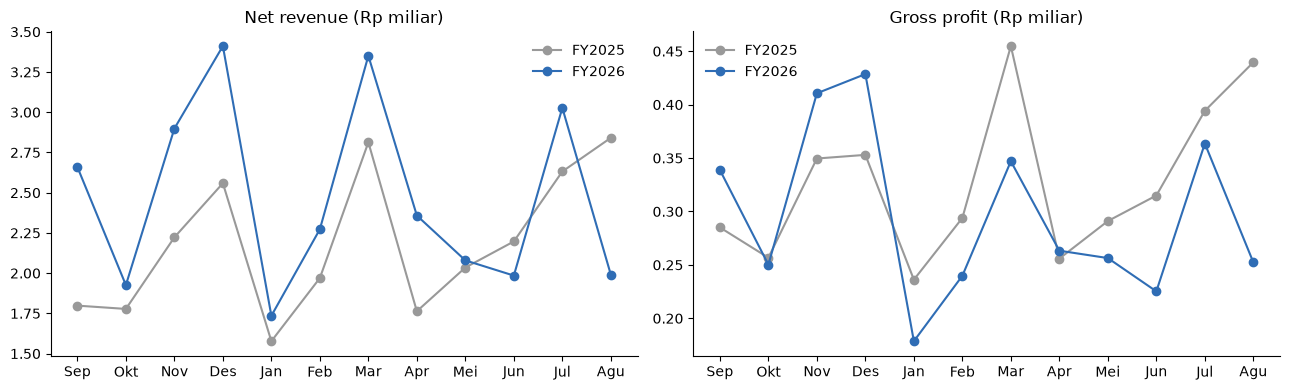

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, kolom, judul in zip(axes, ['net_revenue', 'gross_profit'], ['Net revenue (Rp miliar)', 'Gross profit (Rp miliar)']):
    ax.plot(bln.index, bln[f'{kolom}_FY2025'], marker='o', color='#999', label='FY2025')
    ax.plot(bln.index, bln[f'{kolom}_FY2026'], marker='o', color='#2f6db5', label='FY2026')
    ax.set_title(judul); ax.legend(frameon=False); ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout()
plt.show()

#### Per semester: apakah pertumbuhannya stabil?

In [14]:
sem = df_fy.pivot_table(index='fy_half', columns='fy', values=['net_revenue', 'gross_profit'], aggfunc='sum') / 1e9
hasil = pd.DataFrame({
    'rev_FY2025': sem[('net_revenue', 'FY2025')], 'rev_FY2026': sem[('net_revenue', 'FY2026')],
    'gp_FY2025': sem[('gross_profit', 'FY2025')], 'gp_FY2026': sem[('gross_profit', 'FY2026')],
})
hasil['rev_yoy_pct'] = (hasil['rev_FY2026'] / hasil['rev_FY2025'] - 1) * 100
hasil['gp_yoy_pct'] = (hasil['gp_FY2026'] / hasil['gp_FY2025'] - 1) * 100
hasil['margin_FY2025'] = hasil['gp_FY2025'] / hasil['rev_FY2025'] * 100
hasil['margin_FY2026'] = hasil['gp_FY2026'] / hasil['rev_FY2026'] * 100
hasil

,rev_FY2025,rev_FY2026,gp_FY2025,gp_FY2026,rev_yoy_pct,gp_yoy_pct,margin_FY2025,margin_FY2026
fy_half,,,,,,,,
H1 (Sep-Feb),11.90,14.90,1.77,1.85,25.19,4.07,14.91,12.39
H2 (Mar-Aug),14.28,14.79,2.15,1.71,3.57,-20.58,15.06,11.55


Notes:
- pertumbuhan revenue **melambat tajam**: +25,2% di semester 1 (Sep-Feb) menjadi hanya +3,6% di semester 2 (Mar-Aug)
- gross profit justru memburuk: +4,1% di semester 1 menjadi **-20,6%** di semester 2
- artinya "revenue tumbuh 13%" adalah rata-rata dari dua kondisi yang sangat berbeda. Kondisi terbaru: revenue hampir datar, profit turun dalam

#### Siapa yang tumbuh dan siapa yang turun? (kategori dan channel)

In [15]:
def bandingkan(by):
    t = df_fy.pivot_table(index=by, columns='fy', values=['net_revenue', 'gross_profit'], aggfunc='sum') / 1e9
    out = pd.DataFrame({
        'rev_FY2025': t[('net_revenue', 'FY2025')], 'rev_FY2026': t[('net_revenue', 'FY2026')],
        'gp_FY2025': t[('gross_profit', 'FY2025')], 'gp_FY2026': t[('gross_profit', 'FY2026')],
    })
    out['rev_yoy_pct'] = (out['rev_FY2026'] / out['rev_FY2025'] - 1) * 100
    out['gp_yoy_pct'] = (out['gp_FY2026'] / out['gp_FY2025'] - 1) * 100
    out['margin_FY2025'] = out['gp_FY2025'] / out['rev_FY2025'] * 100
    out['margin_FY2026'] = out['gp_FY2026'] / out['rev_FY2026'] * 100
    out['delta_gp_miliar'] = out['gp_FY2026'] - out['gp_FY2025']
    return out.sort_values('delta_gp_miliar')

bandingkan('category')

,rev_FY2025,rev_FY2026,gp_FY2025,gp_FY2026,rev_yoy_pct,gp_yoy_pct,margin_FY2025,margin_FY2026,delta_gp_miliar
category,,,,,,,,,
Laptop,11.51,14.12,0.81,0.56,22.75,-30.81,7.02,3.96,-0.25
Smartphone,5.10,5.17,0.49,0.29,1.45,-40.07,9.59,5.67,-0.20
Networking,2.02,2.12,0.54,0.51,4.66,-4.55,26.47,24.14,-0.02
Aksesoris,2.44,2.47,0.86,0.85,1.38,-1.63,35.25,34.21,-0.01
Printer & Tinta,1.68,1.83,0.28,0.27,8.88,-3.99,16.85,14.86,-0.01
Peralatan Kantor,3.44,3.98,0.95,1.07,15.69,13.06,27.61,26.99,0.12


In [16]:
bandingkan('channel')

,rev_FY2025,rev_FY2026,gp_FY2025,gp_FY2026,rev_yoy_pct,gp_yoy_pct,margin_FY2025,margin_FY2026,delta_gp_miliar
channel,,,,,,,,,
Online,9.99,9.97,1.39,0.63,-0.19,-54.97,13.90,6.27,-0.76
Offline,16.20,19.72,2.54,2.93,21.78,15.49,15.66,14.85,0.39


Notes:
- **Laptop**: revenue +22,8% tapi gross profit -30,8%. **Smartphone**: revenue +1,4% tapi gross profit -40,1%. Dua kategori ini menyumbang hampir seluruh penurunan profit
- Peralatan Kantor tumbuh sehat (revenue +15,7%, profit +13,1%)
- **Online**: revenue datar (-0,2%) tapi gross profit **-55%** (margin 13,9% -> 6,3%). **Offline**: revenue +21,8%, profit +15,5%
- jadi pertumbuhan revenue datang dari **Offline**, sedangkan kerusakan profit terjadi di **Online**

### Task 2 - Diagnostic: kenapa revenue naik tapi profit turun?

Ada tiga klaim di rapat. Masing-masing dicek dengan data.

#### Klaim 0: "Revenue FY2026 tumbuh 15%"
Angka 15% tergantung cara menghitung revenue. Dicek dengan beberapa definisi:

In [17]:
def tumbuh(frame, rev, gp):
    a = frame.groupby('fy').agg(rev=(rev, 'sum'), gp=(gp, 'sum'))
    return pd.Series({'revenue_FY2025_miliar': a.loc['FY2025', 'rev'] / 1e9, 'revenue_FY2026_miliar': a.loc['FY2026', 'rev'] / 1e9,
                      'revenue_tumbuh_pct': (a.loc['FY2026', 'rev'] / a.loc['FY2025', 'rev'] - 1) * 100,
                      'gp_tumbuh_pct': (a.loc['FY2026', 'gp'] / a.loc['FY2025', 'gp'] - 1) * 100})

fy_all = df[df['fy'] != 'FY2027'].copy()
fy_all['rev_semua'] = fy_all['revenue']                     # semua status, Cancelled ikut dihitung
fy_all['gp_semua'] = fy_all['revenue'] - fy_all['cost']
komp = fy_all[fy_all['status'] == 'Completed']

pd.DataFrame({
    'A. Net revenue (dipakai di analisis): Cancelled=0, return dikurangi, tanpa outlier': tumbuh(df_fy, 'net_revenue', 'gross_profit'),
    'B. Semua status dijumlah (Cancelled ikut), tanpa outlier': tumbuh(fy_all[~fy_all['qty_outlier']], 'rev_semua', 'gp_semua'),
    'C. Semua status dijumlah, outlier ikut': tumbuh(fy_all, 'rev_semua', 'gp_semua'),
    'D. Net revenue, outlier ikut': tumbuh(fy_all, 'net_revenue', 'gross_profit'),
    'E. Hanya Completed (tanpa return), tanpa outlier': tumbuh(komp[~komp['qty_outlier']], 'revenue', 'gp_semua'),
}).T

,revenue_FY2025_miliar,revenue_FY2026_miliar,revenue_tumbuh_pct,gp_tumbuh_pct
"A. Net revenue (dipakai di analisis): Cancelled=0, return dikurangi, tanpa outlier",26.19,29.69,13.40,-9.43
"B. Semua status dijumlah (Cancelled ikut), tanpa outlier",26.76,30.80,15.09,-8.53
"C. Semua status dijumlah, outlier ikut",28.99,32.60,12.49,-9.73
"D. Net revenue, outlier ikut",28.41,31.50,10.87,-10.62
"E. Hanya Completed (tanpa return), tanpa outlier",26.69,30.26,13.37,-10.34


In [18]:
canc = df_fy[df_fy['status'] == 'Cancelled'].groupby('fy')['revenue'].agg(['size', 'sum'])
canc['sum'] = canc['sum'] / 1e9
canc.columns = ['jumlah_order_cancelled', 'nilai_cancelled_miliar']
canc['nilai_cancelled_pct_dari_order'] = df_fy.groupby('fy').apply(
    lambda x: x[x['status'] == 'Cancelled']['revenue'].sum() / x[x['status'] != 'Returned']['revenue'].sum() * 100, include_groups=False)
canc

,jumlah_order_cancelled,nilai_cancelled_miliar,nilai_cancelled_pct_dari_order
fy,,,
FY2025,95,0.58,2.12
FY2026,112,1.11,3.53


Notes:
- angka **15,1%** hanya muncul kalau order **Cancelled ikut dihitung sebagai revenue** (baris B). Dengan revenue yang benar-benar terjadi, pertumbuhannya **13,4%**
- selisihnya karena nilai order yang dibatalkan naik hampir 2x lipat (Rp0,58 -> 1,11 miliar; 2,1% -> 3,5% dari nilai order). Ini pertanda tersendiri yang perlu dicek
- apapun definisinya, **gross profit turun di semua baris** (-8,5% sampai -10,6%). Kesimpulan "profit turun" tidak bergantung pada definisi
- kalau 8 baris outlier Retail ikut dihitung, pertumbuhan revenue turun menjadi 10,9%, jadi angka 15% juga tidak datang dari outlier

#### Dekomposisi: dari mana penurunan gross profit Rp370 juta?

Gross profit per produk = unit x (harga bersih per unit - cost per unit). Perubahan FY2025 -> FY2026 dipecah menjadi:
- **Volume**: unit bertambah x profit per unit FY2025
- **Diskon**: perubahan harga bersih per unit (harga list tidak berubah, jadi ini murni efek diskon) x unit FY2026
- **Cost**: perubahan cost per unit x unit FY2026

In [19]:
n = df_fy[df_fy['status'] != 'Cancelled']
g = n.groupby(['product', 'fy']).agg(Q=('qty', 'sum'), R=('net_revenue', 'sum'), C=('net_cost', 'sum')).unstack()

q25, q26 = g[('Q', 'FY2025')], g[('Q', 'FY2026')]
r25, r26, c25, c26 = g[('R', 'FY2025')], g[('R', 'FY2026')], g[('C', 'FY2025')], g[('C', 'FY2026')]

bridge = pd.DataFrame({
    'volume': (q26 - q25) * (r25 - c25) / q25,
    'diskon': q26 * (r26 / q26 - r25 / q25),
    'cost': -q26 * (c26 / q26 - c25 / q25),
})
bridge['total'] = bridge.sum(axis=1)

gp25, gp26 = (r25 - c25).sum(), (r26 - c26).sum()
tot = bridge.sum() / 1e6
print(f"GP FY2025: {gp25 / 1e6:,.0f} juta -> GP FY2026: {gp26 / 1e6:,.0f} juta (selisih {(gp26 - gp25) / 1e6:,.0f} juta)")
print(f"Volume: {tot['volume']:+,.0f} juta | Diskon: {tot['diskon']:+,.0f} juta | Cost: {tot['cost']:+,.0f} juta | cek total: {tot['total']:+,.0f} juta")
(bridge / 1e6).round(0).sort_values('total')

GP FY2025: 3,925 juta -> GP FY2026: 3,555 juta (selisih -370 juta)
Volume: +541 juta | Diskon: -899 juta | Cost: -13 juta | cek total: -370 juta


,volume,diskon,cost,total
product,,,,
Laptop Axio Pro 15,110.00,-299.00,1.00,-189.00
Smartphone Lumo X,11.00,-124.00,-1.00,-114.00
Smartphone Lumo A5,18.00,-99.00,-0.00,-82.00
Printer InkJet P200,8.00,-63.00,-7.00,-61.00
Headset USB H3,-50.00,-8.00,1.00,-58.00
Laptop Axio 14,32.00,-80.00,-2.00,-50.00
Switch 8 Port S8,-19.00,-17.00,-1.00,-37.00
Laptop Veno 13,79.00,-93.00,4.00,-10.00
Keyboard Mekanik K7,14.00,-14.00,0.00,-0.00


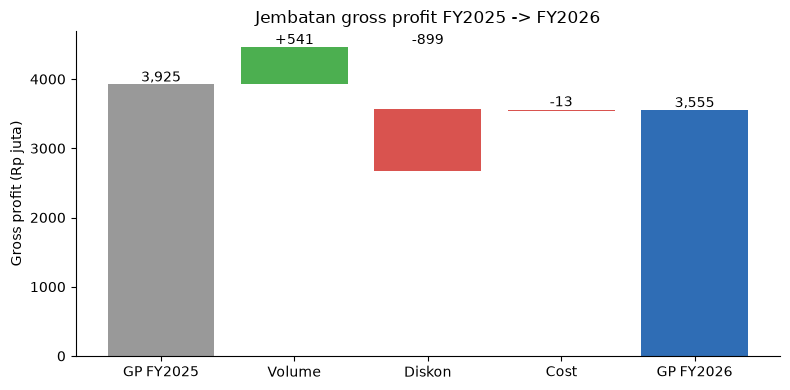

In [20]:
fig, ax = plt.subplots(figsize=(8, 4))
labels = ['GP FY2025', 'Volume', 'Diskon', 'Cost', 'GP FY2026']
vals = [gp25 / 1e6, tot['volume'], tot['diskon'], tot['cost'], gp26 / 1e6]
pos = gp25 / 1e6
for i, (lab, v) in enumerate(zip(labels, vals)):
    if i in (0, 4):
        ax.bar(lab, v, color='#999' if i == 0 else '#2f6db5'); ax.text(i, v + 40, f"{v:,.0f}", ha='center')
    else:
        ax.bar(lab, v, bottom=pos if v >= 0 else pos + v, color='#4caf50' if v >= 0 else '#d9534f')
        ax.text(i, max(pos, pos + v) + 40, f"{v:+,.0f}", ha='center'); pos += v
ax.set_ylabel('Gross profit (Rp juta)'); ax.set_title('Jembatan gross profit FY2025 -> FY2026'); ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout(); plt.show()

Notes:
- **volume** menambah profit sekitar +Rp541 juta (lebih banyak unit terjual)
- **diskon** menghapus sekitar **-Rp899 juta**, jauh lebih besar dari tambahan dari volume
- **cost** hanya -Rp13 juta (praktis nol). Penurunan profit **bukan** berasal dari kenaikan cost
- penurunan terbesar ada di Laptop dan Smartphone (lihat tabel per produk)

#### Klaim 1: "Profit turun karena cost supplier laptop naik"

In [21]:
sale_real = df_sale[~df_sale['cost_imputed']].copy()          # hanya cost asli, tanpa estimasi
sale_real['cost_per_unit'] = sale_real['cost'] / sale_real['qty']
sale_real['rasio_cost'] = sale_real['cost'] / (sale_real['qty'] * sale_real['unit_price'])

uc = sale_real.groupby(['product', 'fy'])['cost_per_unit'].mean().unstack()
uc['perubahan_pct'] = (uc['FY2026'] / uc['FY2025'] - 1) * 100
uc.round(2).loc[['Laptop Axio 14', 'Laptop Axio Pro 15', 'Laptop Veno 13', 'Smartphone Lumo A5', 'Smartphone Lumo X']]

fy,FY2025,FY2026,perubahan_pct
product,,,
Laptop Axio 14,"7,594,755.33","7,595,468.52",0.01
Laptop Axio Pro 15,"11,641,300.00","11,649,713.47",0.07
Laptop Veno 13,"5,554,615.97","5,545,219.09",-0.17
Smartphone Lumo A5,"2,430,502.84","2,431,273.11",0.03
Smartphone Lumo X,"4,797,646.77","4,798,612.59",0.02


In [22]:
rq = sale_real[sale_real['category'] == 'Laptop'].groupby('year_quarter')['rasio_cost'].mean()
print('Cost laptop sebagai % dari harga list, per kuartal kalender:'); print((rq * 100).round(2).to_string())
print(f"\nPerubahan cost per unit semua produk: min {uc['perubahan_pct'].min():+.2f}% | max {uc['perubahan_pct'].max():+.2f}%")

Cost laptop sebagai % dari harga list, per kuartal kalender:
year_quarter
2024-Q3   89.51
2024-Q4   89.47
2025-Q1   89.47
2025-Q2   89.45
2025-Q3   89.53
2025-Q4   89.44
2026-Q1   89.51
2026-Q2   89.47
2026-Q3   89.51

Perubahan cost per unit semua produk: min -0.17% | max +0.19%


Notes:
- cost per unit laptop **tidak berubah**: perubahan FY2025 -> FY2026 di bawah 0,2% untuk semua produk (rata-rata Axio 14 Rp7,59 juta di kedua tahun)
- cost laptop konstan di 89,5% dari harga list di setiap kuartal. Tidak ada tanda kenaikan, bahkan sebelum dan sesudah September 2025
- jadi dalam data, klaim ini **tidak didukung**. Penurunan margin laptop (7,0% -> 4,0%) berasal dari diskon
- **keterbatasan**: kolom *cost* bisa saja berupa standard cost yang tidak ikut berubah. Kalau supplier memang menaikkan harga tetapi belum tercatat di sistem, data ini tidak akan menunjukkannya. Perlu dikonfirmasi ke Finance/Procurement dengan invoice supplier

#### Klaim 2: "Promosi mendorong pertumbuhan, jadi tambah promosi tahun depan"

Diskon besar (>= 20%) **tidak ada sama sekali di FY2025**. Dicek apa yang terjadi setelah diskon tersebut muncul (Sep 2025):

In [23]:
t = df_sale.groupby(['fy', 'deep_disc']).agg(
    net_revenue_miliar=('net_revenue', lambda s: s.sum() / 1e9),
    gross_profit_juta=('gross_profit', lambda s: s.sum() / 1e6),
    unit=('qty', 'sum'),
    order=('order_id', 'size'),
)
t['margin_pct'] = t['gross_profit_juta'] / (t['net_revenue_miliar'] * 1e3) * 100
t

net_revenue_miliar  gross_profit_juta   unit  order  margin_pct
fy     deep_disc                                                                 
FY2025 False                   26.69           4,026.09  17191   3146       15.08
FY2026 False                   26.56           3,982.28  16552   2905       15.00
       True                     3.70            -372.61   2836    575      -10.06

In [24]:
a = df_sale.groupby(['fy', 'deep_disc'])[['net_revenue', 'gross_profit']].sum()
reg25, reg26 = a.loc[('FY2025', False)], a.loc[('FY2026', False)]
deep26 = a.loc[('FY2026', True)]
print(f"Penjualan TANPA diskon besar: revenue {reg25['net_revenue'] / 1e9:.2f} -> {reg26['net_revenue'] / 1e9:.2f} miliar ({(reg26['net_revenue'] / reg25['net_revenue'] - 1) * 100:+.1f}%)")
print(f"Penjualan DENGAN diskon besar: revenue {deep26['net_revenue'] / 1e9:.2f} miliar, gross profit {deep26['gross_profit'] / 1e6:+,.0f} juta")
dp = df_sale[df_sale['deep_disc']]
print(f"Order diskon besar: {len(dp)} | di Online: {(dp['channel'] == 'Online').mean() * 100:.0f}% | ke customer Retail: {(dp['customer_type'] == 'Retail').mean() * 100:.0f}% | rugi (GP < 0): {(dp['gross_profit'] < 0).mean() * 100:.0f}%")
print(f"Pertumbuhan revenue order selesai: +{(a.loc['FY2026', 'net_revenue'].sum() / a.loc['FY2025', 'net_revenue'].sum() - 1) * 100:.1f}%  | seluruhnya (dan lebih) berasal dari baris diskon besar")

Penjualan TANPA diskon besar: revenue 26.69 -> 26.56 miliar (-0.5%)
Penjualan DENGAN diskon besar: revenue 3.70 miliar, gross profit -373 juta
Order diskon besar: 575 | di Online: 77% | ke customer Retail: 58% | rugi (GP < 0): 46%
Pertumbuhan revenue order selesai: +13.4%  | seluruhnya (dan lebih) berasal dari baris diskon besar


Notes:
- penjualan **tanpa** diskon besar praktis **tidak tumbuh** (Rp26,69 -> 26,56 miliar, -0,5%) dan jumlah ordernya turun (3.146 -> 2.905)
- seluruh tambahan revenue (Rp3,70 miliar) datang dari order dengan diskon >= 20%, dan order-order itu **rugi** (gross profit -Rp373 juta, margin -10%)
- jadi pernyataan Marketing "promosi mendorong pertumbuhan" benar secara angka, tetapi pertumbuhan itu dibeli dengan kerugian

#### Di channel mana promosi bekerja?

In [25]:
ch = df_fy.groupby(['channel', 'fy', 'deep_disc'])['net_revenue'].sum().unstack([1, 2]) / 1e9
ch.columns = [f'{a}_{"diskon_besar" if b else "reguler"}' for a, b in ch.columns]
ch['total_FY2025'] = ch['FY2025_reguler']
ch['total_FY2026'] = ch['FY2026_reguler'] + ch['FY2026_diskon_besar']
ch['pertumbuhan_pct'] = (ch['total_FY2026'] / ch['total_FY2025'] - 1) * 100
ch['porsi_diskon_besar_di_FY2026_pct'] = ch['FY2026_diskon_besar'] / ch['total_FY2026'] * 100
ch[['FY2025_reguler', 'FY2026_reguler', 'FY2026_diskon_besar', 'total_FY2025', 'total_FY2026', 'pertumbuhan_pct', 'porsi_diskon_besar_di_FY2026_pct']]

,FY2025_reguler,FY2026_reguler,FY2026_diskon_besar,total_FY2025,total_FY2026,pertumbuhan_pct,porsi_diskon_besar_di_FY2026_pct
channel,,,,,,,
Offline,16.20,18.94,0.78,16.20,19.72,21.78,3.96
Online,9.99,7.16,2.81,9.99,9.97,-0.19,28.20


In [26]:
on = df_sale[df_sale['channel'] == 'Online']
oo = on.groupby('fy').agg(order=('order_id', 'size'), nilai_per_order_juta=('net_revenue', lambda s: s.mean() / 1e6))
oo['rata2_diskon_pct'] = on.groupby('fy').apply(lambda x: (x['list_value'].sum() - x['net_revenue'].sum()) / x['list_value'].sum() * 100, include_groups=False)
oo['margin_pct'] = on.groupby('fy').apply(lambda x: x['gross_profit'].sum() / x['net_revenue'].sum() * 100, include_groups=False)
oo

,order,nilai_per_order_juta,rata2_diskon_pct,margin_pct
fy,,,,
FY2025,1079,9.37,6.36,13.93
FY2026,1348,7.54,12.44,6.28


Notes:
- **77% dari baris diskon besar ada di Online**. Hasilnya: revenue Online **tidak tumbuh** (9,99 -> 9,97 miliar). Penjualan Online reguler turun dari 9,99 menjadi 7,16 miliar, dan "diganti" oleh penjualan berdiskon 2,81 miliar
- jumlah order Online naik 25%, tetapi nilai per order turun (9,4 -> 7,5 juta) dan rata-rata diskon naik dari 6,4% ke 12,4%. Lebih banyak order, uang yang masuk sama, profit lebih kecil
- pertumbuhan revenue sebenarnya datang dari **Offline** (+21,8%, dan hampir semuanya tanpa diskon besar: hanya 4% dari revenue Offline FY2026)
- **kehati-hatian**: ini menunjukkan korelasi yang kuat, bukan bukti sebab-akibat. Kami tidak punya kalender promo atau biaya marketing. Kemungkinan lain (misalnya permintaan Online yang memang turun) tidak bisa dikesampingkan. Karena itu rekomendasi disertai uji coba terukur di Task 4

#### Pertumbuhan Offline: dari mana?

In [27]:
off = df_sale[df_sale['channel'] == 'Offline']
x = off.pivot_table(index='customer_type', columns='fy', values='net_revenue', aggfunc='sum') / 1e9
x['pertumbuhan_pct'] = (x['FY2026'] / x['FY2025'] - 1) * 100
x['porsi_dari_pertumbuhan_pct'] = (x['FY2026'] - x['FY2025']) / (x['FY2026'] - x['FY2025']).sum() * 100
x

fy,FY2025,FY2026,pertumbuhan_pct,porsi_dari_pertumbuhan_pct
customer_type,,,,
Korporat,5.55,7.27,30.89,48.69
Retail,5.22,5.95,14.12,20.91
UMKM,5.81,6.88,18.42,30.39


Notes:
- pertumbuhan Offline terutama dari **Korporat** (+30,9%, ~49% dari tambahan revenue Offline), lalu UMKM (+18,4%) dan Retail (+14,1%)
- margin Offline tetap sehat (14,9% di FY2026). Sumber pertumbuhan yang sehat ini yang perlu dijaga

#### Ringkasan diagnostik

| Klaim | Hasil | Bukti |
|---|---|---|
| "Revenue naik 15%" | **Kurang tepat**: 13,4% | 15% hanya jika order Cancelled ikut dihitung |
| "Cost supplier laptop naik" | **Tidak didukung data** | cost per unit laptop konstan; dekomposisi: cost hanya -Rp13 juta dari -Rp370 juta |
| "Promosi mendorong pertumbuhan" | **Benar secara angka, tapi merugikan** | diskon >= 20% menyumbang seluruh pertumbuhan dengan gross profit -Rp373 juta; Online (77% promo) tidak tumbuh |
| **Penyebab sebenarnya** | **Diskon**, bukan cost | efek diskon -Rp899 juta vs volume +Rp541 juta |

### Task 3 - Predictive: perkiraan revenue 3 bulan ke depan

Data berakhir 15 Sep 2026, jadi tiga bulan ke depan = **Oktober, November, Desember 2026**.

Metode sederhana dan transparan (tanpa machine learning):
1. hitung **indeks musiman** tiap bulan (revenue bulan itu dibanding rata-rata bulanan tahunnya, dirata-rata 2 tahun)
2. buang pengaruh musim dari 12 bulan terakhir untuk mendapat **level penjualan** saat ini
3. perkiraan = level x indeks musiman bulan tersebut

Karena pertumbuhan sedang melambat (lihat Task 1), tiga skenario dipakai, bukan satu angka.

In [28]:
bulanan = df_fy.groupby('year_month')['net_revenue'].sum() / 1e9
fy25 = bulanan['2024-09':'2025-08']
fy26 = bulanan['2025-09':'2026-08']
urutan = [9, 10, 11, 12, 1, 2, 3, 4, 5, 6, 7, 8]

indeks = pd.Series((fy25.values / fy25.mean() + fy26.values / fy26.mean()) / 2, index=urutan)
des = pd.Series(fy26.values / indeks.values, index=urutan)       # revenue FY2026 tanpa pengaruh musim

bulan_kal = {9: 'Sep', 10: 'Okt', 11: 'Nov', 12: 'Des', 1: 'Jan', 2: 'Feb', 3: 'Mar', 4: 'Apr', 5: 'Mei', 6: 'Jun', 7: 'Jul', 8: 'Agu'}

pd.DataFrame({'indeks_musiman': indeks.round(3), 'revenue_FY2026_miliar': fy26.values, 'setelah_buang_musim': des.round(2)}).rename(index=bulan_kal)

,indeks_musiman,revenue_FY2026_miliar,setelah_buang_musim
Sep,0.95,2.66,2.80
Okt,0.80,1.93,2.42
Nov,1.09,2.90,2.65
Des,1.28,3.41,2.67
Jan,0.71,1.74,2.44
Feb,0.91,2.27,2.50
Mar,1.32,3.35,2.54
Apr,0.88,2.36,2.68
Mei,0.89,2.08,2.35
Jun,0.90,1.98,2.19


Notes:
- puncak musiman: **Maret (1,32), Desember (1,28), Juli (1,22)**; terendah **Januari (0,71)** dan Oktober (0,80)
- setelah musim dibuang, level penjualan terlihat **menurun sepanjang tahun**: rata-rata 2,58 miliar/bulan di Sep-Feb, tinggal 2,36 di 6 bulan terakhir dan 2,19 di 3 bulan terakhir

#### Uji akurasi: kalau metode ini dipakai tahun lalu, seberapa tepat?

In [29]:
# simulasi: anggap kita berada di akhir Mei 2026, perkirakan Jun-Agu 2026 lalu bandingkan dengan kenyataan
aktual = fy26.iloc[9:].values
idx25 = fy25.values / fy25.mean()
level_known = (fy26.iloc[3:9].values / idx25[3:9]).mean()                     # level dari Des-Mei
f_level = level_known * idx25[9:]                                                # metode level x musim
g_h = fy26.iloc[3:9].sum() / fy25.iloc[3:9].sum() - 1
f_naive = fy25.iloc[9:].values * (1 + g_h)                                        # musim lalu x pertumbuhan YoY

uji = pd.DataFrame({'aktual': aktual, 'level_x_musim': f_level, 'musim_lalu_x_growth': f_naive}, index=['Jun', 'Jul', 'Agu'])
print(uji.round(2).to_string())
mape = lambda f: np.mean(np.abs(f - aktual) / aktual) * 100
print(f"\nError rata-rata per bulan: level_x_musim {mape(f_level):.0f}% | musim_lalu_x_growth {mape(f_naive):.0f}%")
print(f"Error total 3 bulan: level_x_musim {(f_level.sum() / aktual.sum() - 1) * 100:+.0f}% | musim_lalu_x_growth {(f_naive.sum() / aktual.sum() - 1) * 100:+.0f}%")

     aktual  level_x_musim  musim_lalu_x_growth
Jun    1.98           2.61                 2.63
Jul    3.03           3.13                 3.15
Agu    1.99           3.38                 3.40

Error rata-rata per bulan: level_x_musim 35% | musim_lalu_x_growth 36%
Error total 3 bulan: level_x_musim +30% | musim_lalu_x_growth +31%


Notes:
- kedua metode **terlalu optimis ~30%** untuk Jun-Agu 2026, karena penjualan melambat lebih cepat daripada yang terlihat dari data sebelumnya (terutama Agustus yang -30% YoY)
- pelajarannya: angka bulanan sulit diprediksi (error rata-rata ~35% per bulan). Hasil di bawah harus dibaca sebagai **rentang**, bukan angka pasti, dan skenario bawah sengaja dibuat lebih konservatif

#### Perkiraan Okt-Des 2026

In [30]:
target = [10, 11, 12]
lvl_6, lvl_3 = des.iloc[-6:].mean(), des.iloc[-3:].mean()
g_h2 = fy26.iloc[6:].sum() / fy25.iloc[6:].sum() - 1          # pertumbuhan YoY semester 2
g_fy = fy26.sum() / fy25.sum() - 1

basis_okt_des = fy26.iloc[1:4].values                          # Okt-Des 2025 (aktual)
skenario = pd.DataFrame({
    'Okt-Des 2025 (aktual)': basis_okt_des,
    'Rendah: level 3 bln terakhir': [lvl_3 * indeks[m] for m in target],
    'Dasar: level 6 bln terakhir': [lvl_6 * indeks[m] for m in target],
    'Tinggi: musim lalu x growth semester-2': basis_okt_des * (1 + g_h2),
}, index=['Okt 2026', 'Nov 2026', 'Des 2026'])
skenario.loc['Total 3 bulan'] = skenario.sum()
skenario.loc['vs Okt-Des 2025 (%)'] = (skenario.loc['Total 3 bulan'] / skenario.loc['Total 3 bulan', 'Okt-Des 2025 (aktual)'] - 1) * 100
skenario.round(2)

,Okt-Des 2025 (aktual),Rendah: level 3 bln terakhir,Dasar: level 6 bln terakhir,Tinggi: musim lalu x growth semester-2
Okt 2026,1.93,1.75,1.88,1.99
Nov 2026,2.90,2.40,2.58,3.00
Des 2026,3.41,2.80,3.01,3.53
Total 3 bulan,8.24,6.94,7.46,8.53
vs Okt-Des 2025 (%),0.00,-15.70,-9.40,3.57


In [31]:
# sanity check: kecepatan penjualan 1-15 Sep 2026 yang sudah terjadi
sep = df[(df['fy'] == 'FY2027') & ~df['qty_outlier']]['net_revenue'].sum() / 1e9
print(f"Revenue 1-15 Sep 2026: Rp{sep:.2f} miliar -> setara Rp{sep / 15 * 30:.2f} miliar per bulan")
print(f"Perkiraan model untuk Sep penuh: level_6 x indeks = Rp{lvl_6 * indeks[9]:.2f} | musim lalu x growth = Rp{fy26.iloc[0] * (1 + g_h2):.2f} miliar")

# margin yang dipakai untuk perkiraan gross profit: 6 bulan terakhir (Mar-Agu 2026)
m6 = df_fy[df_fy['year_month'] >= '2026-03']
margin_6 = m6['gross_profit'].sum() / m6['net_revenue'].sum()
gp_fc = skenario.loc['Total 3 bulan', ['Rendah: level 3 bln terakhir', 'Dasar: level 6 bln terakhir', 'Tinggi: musim lalu x growth semester-2']] * margin_6
print(f"\nMargin 6 bulan terakhir: {margin_6 * 100:.1f}%  -> perkiraan gross profit Okt-Des 2026 (kondisi sekarang tanpa perubahan): ")
print((gp_fc * 1e3).round(0).to_string(), ' (Rp juta)')

Revenue 1-15 Sep 2026: Rp1.27 miliar -> setara Rp2.53 miliar per bulan
Perkiraan model untuk Sep penuh: level_6 x indeks = Rp2.24 | musim lalu x growth = Rp2.75 miliar

Margin 6 bulan terakhir: 11.5%  -> perkiraan gross profit Okt-Des 2026 (kondisi sekarang tanpa perubahan): 
Rendah: level 3 bln terakhir             802.00
Dasar: level 6 bln terakhir              862.00
Tinggi: musim lalu x growth semester-2   985.00  (Rp juta)


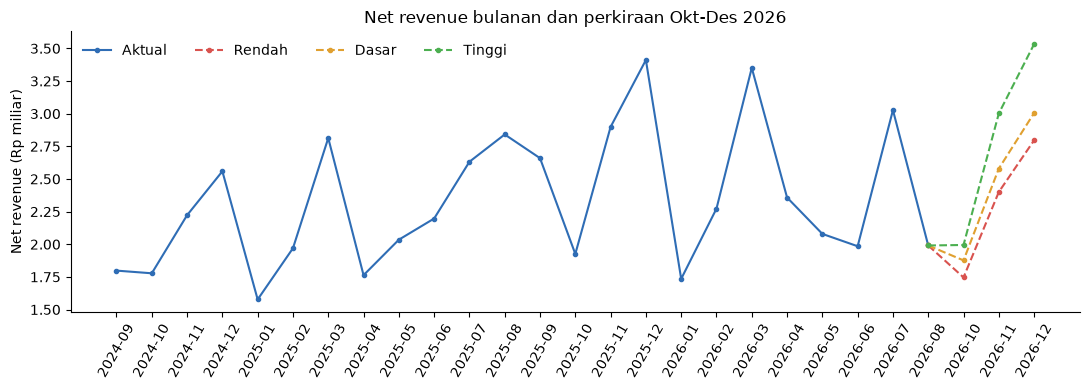

In [32]:
fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(bulanan[:'2026-08'].index, bulanan[:'2026-08'].values, marker='o', ms=3, color='#2f6db5', label='Aktual')
fc_idx = ['2026-10', '2026-11', '2026-12']
for kol, warna, lab in [('Rendah: level 3 bln terakhir', '#d9534f', 'Rendah'), ('Dasar: level 6 bln terakhir', '#e0a030', 'Dasar'), ('Tinggi: musim lalu x growth semester-2', '#4caf50', 'Tinggi')]:
    ax.plot(['2026-08'] + fc_idx, [bulanan['2026-08']] + list(skenario.loc[['Okt 2026', 'Nov 2026', 'Des 2026'], kol]), ls='--', marker='o', ms=3, color=warna, label=lab)
ax.tick_params(axis='x', rotation=60); ax.set_ylabel('Net revenue (Rp miliar)'); ax.legend(frameon=False, ncol=4)
ax.set_title('Net revenue bulanan dan perkiraan Okt-Des 2026'); ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout(); plt.show()

Notes:
- perkiraan **Okt-Des 2026: Rp6,9 - 8,5 miliar, skenario dasar Rp7,5 miliar** (turun sekitar 9% dibanding Okt-Des 2025 yang Rp8,2 miliar)
- skenario dasar lebih rendah dari tahun lalu karena Okt-Des 2025 adalah periode awal promo besar (pertumbuhan YoY saat itu +8% sampai +33%), sementara level penjualan sekarang sudah lebih rendah
- pertumbuhan 13,4% setahun penuh **tidak dipakai** untuk ekstrapolasi karena pertumbuhan terbaru sudah jauh di bawahnya (semester 2: +3,6%; 4 bulan terakhir negatif)
- cek kewajaran: penjualan 1-15 Sep (Rp1,27 miliar) setara ~Rp2,5 miliar/bulan, di antara perkiraan model (2,24 dan 2,75)
- dengan margin 6 bulan terakhir (11,5%), gross profit Okt-Des diperkirakan **Rp0,80 - 0,99 miliar** (dasar Rp0,86 miliar) bila tidak ada perubahan kebijakan
- **asumsi**: pola musiman 2 tahun terakhir berulang, tidak ada perubahan harga/promo besar, tidak ada kejadian luar biasa. Uji akurasi menunjukkan error bisa sekitar 30% untuk 3 bulan, jadi gunakan sebagai rentang

### Task 4 - Prescriptive: apa yang harus dilakukan?

Dasar rekomendasi: penurunan profit berasal dari diskon >= 20% yang muncul sejak Sep 2025, terutama di Online dan pada Laptop/Smartphone. Cost tidak berubah, jadi **batas aman diskon bisa dihitung langsung**: diskon maksimum sebelum rugi = 1 - (cost / harga list).

In [33]:
cr = df_sale[~df_sale['cost_imputed']].groupby('category').apply(lambda x: x['cost'].sum() / x['list_value'].sum(), include_groups=False)
be = pd.DataFrame({'cost_pct_dari_harga_list': cr * 100, 'diskon_break_even_pct': (1 - cr) * 100})
be['porsi_baris_diskon_besar_pct'] = df_sale[df_sale['fy'] == 'FY2026'].groupby('category')['deep_disc'].mean() * 100
be['gross_profit_diskon_besar_juta'] = df_sale[df_sale['deep_disc']].groupby('category')['gross_profit'].sum() / 1e6
be.sort_values('diskon_break_even_pct')

,cost_pct_dari_harga_list,diskon_break_even_pct,porsi_baris_diskon_besar_pct,gross_profit_diskon_besar_juta
category,,,,
Laptop,89.49,10.51,14.77,-339.45
Smartphone,87.07,12.93,18.40,-134.79
Printer & Tinta,78.10,21.90,17.30,-9.00
Networking,70.25,29.75,19.74,19.50
Peralatan Kantor,68.51,31.49,15.37,46.80
Aksesoris,61.12,38.88,15.55,44.34


Notes:
- diskon break-even: **Laptop ~10,5%, Smartphone ~13%, Printer & Tinta ~22%**, sedangkan Aksesoris ~39%
- diskon 20-30% pada Laptop dan Smartphone **pasti rugi**; dua kategori ini menanggung hampir seluruh kerugian diskon besar (Laptop -Rp339 juta, Smartphone -Rp135 juta)

#### Simulasi dampak (basis FY2026, order selesai)

Dua kebijakan diuji pada transaksi FY2026 yang sebenarnya:
- **Aksi 1** - batas diskon maksimum **15%** untuk semua produk
- **Aksi 2** - Aksi 1 + batas **10%** untuk Laptop dan Smartphone (mendekati titik impas)

Karena tidak tahu berapa pelanggan yang tetap membeli jika diskonnya lebih kecil, dicoba empat skenario **retensi** (persentase order yang terdampak tetap terjadi dengan diskon baru): 100%, 70%, 50%, dan 0% (semua order tersebut hilang).

In [34]:
c = df_sale[df_sale['fy'] == 'FY2026'].copy()
base_rev, base_gp = c['revenue'].sum(), (c['revenue'] - c['cost']).sum()
fy25_c = df_sale[df_sale['fy'] == 'FY2025']
print(f"FY2025 order selesai: revenue {fy25_c['revenue'].sum() / 1e9:.2f} miliar | GP {(fy25_c['revenue'] - fy25_c['cost']).sum() / 1e9:.2f} miliar ({(fy25_c['revenue'] - fy25_c['cost']).sum() / fy25_c['revenue'].sum() * 100:.1f}%)")
print(f"FY2026 order selesai: revenue {base_rev / 1e9:.2f} miliar | GP {base_gp / 1e9:.2f} miliar ({base_gp / base_rev * 100:.1f}%)")

def simulasi(frame, cap, retensi):
    cap = cap.loc[frame.index] if isinstance(cap, pd.Series) else cap
    terdampak = frame['discount'] > cap
    rev_baru = np.where(terdampak, frame['qty'] * frame['unit_price'] * (1 - cap), frame['revenue'])
    tetap = np.where(terdampak, retensi, 1.0)
    rev = (rev_baru * tetap).sum()
    gp = ((rev_baru - frame['cost']) * tetap).sum()
    return rev, gp

cap1 = pd.Series(0.15, index=c.index)
cap2 = c['category'].map({'Laptop': 0.10, 'Smartphone': 0.10}).fillna(0.15)

baris = []
for nama, cap in [('Aksi 1: batas 15%', cap1), ('Aksi 2: 15% + Laptop/HP 10%', cap2)]:
    for r in [1.0, 0.7, 0.5, 0.0]:
        rev, gp = simulasi(c, cap, r)
        baris.append({'kebijakan': nama, 'retensi_pct': r * 100, 'order_terdampak': int((c['discount'] > cap).sum()),
                      'delta_revenue_juta': (rev - base_rev) / 1e6, 'delta_gross_profit_juta': (gp - base_gp) / 1e6,
                      'revenue_baru_miliar': rev / 1e9, 'gross_profit_baru_miliar': gp / 1e9, 'margin_baru_pct': gp / rev * 100})
sim = pd.DataFrame(baris)
sim.round(2)

FY2025 order selesai: revenue 26.69 miliar | GP 4.03 miliar (15.1%)
FY2026 order selesai: revenue 30.26 miliar | GP 3.61 miliar (11.9%)


,kebijakan,retensi_pct,order_terdampak,delta_revenue_juta,delta_gross_profit_juta,revenue_baru_miliar,gross_profit_baru_miliar,margin_baru_pct
0,Aksi 1: batas 15%,100.00,575,502.80,502.80,30.76,4.11,13.37
1,Aksi 1: batas 15%,70.00,575,-759.26,463.74,29.50,4.07,13.81
2,Aksi 1: batas 15%,50.00,575,"-1,600.62",437.70,28.66,4.05,14.12
3,Aksi 1: batas 15%,0.00,575,"-3,704.04",372.61,26.56,3.98,15.00
4,Aksi 2: 15% + Laptop/HP 10%,100.00,615,705.13,705.13,30.97,4.31,13.93
5,Aksi 2: 15% + Laptop/HP 10%,70.00,615,-785.08,613.18,29.48,4.22,14.33
6,Aksi 2: 15% + Laptop/HP 10%,50.00,615,"-1,778.55",551.87,28.48,4.16,14.61
7,Aksi 2: 15% + Laptop/HP 10%,0.00,615,"-4,262.24",398.62,26.00,4.01,15.42


Notes:
- **Aksi 1** menaikkan gross profit **di semua skenario**, dari +Rp373 juta (semua order terdampak hilang) sampai +Rp503 juta (semua tetap membeli). Alasannya: order diskon besar sekarang rugi, jadi kehilangan sebagian pun tidak menambah kerugian
- pada retensi 70% (asumsi tengah), gross profit naik ke ~Rp4,07 miliar, **kembali ke level FY2025 (Rp4,03 miliar)**, sementara revenue tetap sekitar Rp29,5 miliar (masih +10% dibanding FY2025) dan margin naik dari 11,9% ke ~13,8%
- **Aksi 2** menambah +Rp26 sampai +Rp202 juta di atas Aksi 1 (retensi 0-100%); lebih kecil, tapi menutup celah diskon 11-15% pada Laptop/Smartphone yang masih di bawah titik impas
- angka ini adalah **estimasi atas data FY2026**; hasil nyata tergantung respons pelanggan, sehingga perlu uji coba (lihat bawah)

In [35]:
# dampak untuk Okt-Des 2026: terapkan ke order Okt-Des 2025 lalu skala ke perkiraan dasar
q4 = c[c['year_month'].isin(['2025-10', '2025-11', '2025-12'])]
faktor = skenario.loc['Total 3 bulan', 'Dasar: level 6 bln terakhir'] * 1e9 / df_fy[df_fy['year_month'].isin(['2025-10', '2025-11', '2025-12'])]['net_revenue'].sum()
q4_base_gp = (q4['revenue'] - q4['cost']).sum()

out = []
for r in [1.0, 0.7, 0.5]:
    rev, gp = simulasi(q4, cap1, r)
    out.append({'retensi_pct': r * 100, 'tambahan_gp_okt_des_juta': (gp - q4_base_gp) * faktor / 1e6})
pd.DataFrame(out).round(0)

,retensi_pct,tambahan_gp_okt_des_juta
0,100.00,110.00
1,70.00,97.00
2,50.00,88.00


Notes: bila Aksi 1 berlaku mulai Oktober, tambahan gross profit Okt-Des 2026 diperkirakan sekitar **Rp88 - 110 juta** (di atas perkiraan dasar Rp0,86 miliar), tergantung retensi pelanggan

#### Rekomendasi

| # | Aksi | Alasan (bukti) | Dampak yang diharapkan |
|---|---|---|---|
| 1 | **Batasi diskon maksimum 15%** untuk semua produk dan channel, mulai dari Online (butuh approval di atas batas) | 575 order diskon >= 20% menghasilkan revenue Rp3,7 miliar dengan gross profit **-Rp373 juta**; mayoritas di Online | Gross profit **+Rp373 - 503 juta per tahun**; profit kembali ke level FY2025 (retensi 70%: ~Rp4,07 miliar), margin ~13,8% |
| 2 | **Diskon Laptop & Smartphone maksimum 10%** (mendekati titik impas 10,5% dan 13%); arahkan promosi ke kategori margin tinggi (Aksesoris, Peralatan Kantor, Networking: margin 25-35%) | Laptop & Smartphone = 64% revenue tapi margin 5-8%; kehilangan profit terbesar ada di sini | Tambahan **+Rp26 - 202 juta per tahun** di atas Aksi 1 |
| 3 | **Ganti ukuran kinerja Sales dan Marketing dari revenue ke gross profit**; pantau tiap bulan: margin >= 14%, porsi order diskon >= 20% = 0%, margin Online >= 12%. Uji coba dulu 3 bulan di Online | Revenue naik 13% menutupi profit yang turun 9%. Dampak promo hanya terbukti korelatif | Mencegah kejadian berulang. Hasil uji coba (3 bulan, dibandingkan Offline sebagai pembanding) menentukan apakah kebijakan dilanjutkan |

**Yang jangan dilakukan**: menambah promosi tahun depan seperti usulan Marketing. Dengan pola sekarang, setiap tambahan promo menambah revenue tetapi mengurangi profit. Dan menunggu penurunan cost supplier tidak akan membantu karena cost tidak naik.

### Asumsi dan keterbatasan

| Topik | Asumsi / keterbatasan | Dampak |
|---|---|---|
| Data | Memakai hasil cleaning Soal 1. Cost Networking (~60% baris) adalah estimasi; 8 baris outlier Retail dikeluarkan | Margin total bergeser ~0,5 poin; pertumbuhan revenue 10,9% bila outlier ikut |
| Klaim cost supplier | Kolom *cost* mungkin standard cost. Bisa saja kenaikan harga supplier belum tercatat | Perlu dicek ke Finance/Procurement dengan invoice supplier |
| Sebab-akibat promo | Tidak ada kalender promo atau biaya marketing. Hubungan promo-penjualan bersifat korelasi | Itu sebabnya Aksi 3 berupa uji coba terukur |
| Cancelled | Order *Cancelled* naik 2x lipat (nilai) dan tidak dianalisis lebih jauh (alasan tidak ada di data) | Perlu ditelusuri tersendiri |
| Perkiraan | Metode sederhana, 2 tahun data, pola musim diasumsikan berulang. Uji akurasi: ~30% error 3 bulan | Gunakan rentang, bukan titik |
| Simulasi kebijakan | Memakai transaksi FY2026 apa adanya; retensi pelanggan tidak diketahui sehingga diuji 0-100%; biaya promosi tidak ikut dihitung | Dampak nyata bisa berbeda |
| Periode | 1-15 Sep 2026 tidak masuk FY2026 | Perbandingan FY bersih dari bulan yang belum penuh |

### Task 5 - Executive Summary

Ringkasan satu halaman untuk Board ada di file `Executive_Summary.md` (isinya sama dengan di bawah, dengan angka yang sama dengan notebook ini).

# Executive Summary: Revenue naik, profit turun

**Untuk:** Board of Directors, PT Sinar Niaga Nusantara | **Periode:** FY2025 (Sep 2024-Agu 2025) vs FY2026 (Sep 2025-Agu 2026)

**Jawaban singkat:** profit turun karena **diskon besar (20-30%) yang mulai diberikan sejak September 2025**, terutama di Online, bukan karena cost supplier. Diskon itu menambah revenue, tetapi setiap penjualannya rugi.

## 1. Apa yang terjadi
- Net revenue **+13,4%** (Rp26,2 -> 29,7 miliar). Angka 15% hanya muncul jika order yang dibatalkan ikut dihitung.
- Gross profit **-9,4%** (Rp3,93 -> 3,55 miliar); margin turun dari **15,0% ke 12,0%**.
- Pertumbuhan melambat: revenue **+25%** di Sep-Feb, tinggal **+3,6%** di Mar-Agu, sementara profit semester kedua **-20,6%**.

## 2. Kenapa
- Perubahan profit: volume **+Rp541 juta**, diskon **-Rp899 juta**, cost **-Rp13 juta**. Total -Rp370 juta.
- **"Cost supplier laptop naik": tidak didukung data.** Cost per unit laptop tidak berubah (selisih <0,2%). Perlu konfirmasi invoice supplier ke Finance.
- **"Promosi mendorong pertumbuhan": benar secara angka, tetapi merugi.** Diskon >= 20% tidak ada di FY2025. Di FY2026, penjualan tanpa diskon besar tidak tumbuh (-0,5%); seluruh pertumbuhan datang dari 575 order diskon besar dengan **gross profit -Rp373 juta** (margin -10%).
- **Online** (77% order diskon besar): revenue datar (-0,2%), profit **-55%**. **Offline**: revenue +21,8%, profit +15,5%, hampir tanpa diskon besar. Pertumbuhan sehat ada di Offline.

## 3. Perkiraan Okt-Des 2026
- Revenue **Rp6,9 - 8,5 miliar, skenario dasar Rp7,5 miliar** (sekitar 9% di bawah Okt-Des 2025). Gross profit dasar **~Rp0,86 miliar** bila kebijakan tidak berubah.
- Uji historis menunjukkan error metode ini bisa ~30% untuk 3 bulan, jadi gunakan sebagai rentang.

## 4. Rekomendasi
| Aksi | Dampak yang diharapkan |
|---|---|
| **1. Batasi diskon maksimum 15%** semua produk, mulai dari Online | Gross profit **+Rp373 - 503 juta/tahun** (tergantung berapa pelanggan tetap membeli). Pada asumsi tengah, profit kembali ke level FY2025 (~Rp4,07 miliar) dan revenue tetap ~+10% |
| **2. Diskon Laptop & Smartphone maks. 10%** (titik impas 10,5% dan 13%); arahkan promosi ke Aksesoris, Peralatan Kantor, Networking (margin 25-35%) | Tambahan **+Rp26 - 202 juta/tahun** di atas Aksi 1 |
| **3. Nilai Sales & Marketing dari gross profit, bukan revenue.** Pantau bulanan: margin >= 14%, order diskon >= 20% = 0. Uji coba 3 bulan di Online | Mencegah terulang; hasil uji coba menentukan kelanjutan |

**Jangan menambah promosi seperti usulan Marketing** dengan pola saat ini: tiap tambahan promo menambah revenue tetapi mengurangi profit.

## Keterbatasan
- Hubungan promo dan penjualan bersifat korelasi (tidak ada kalender promo atau biaya marketing), maka Aksi 3 berupa uji coba.
- Cost Networking (~60% baris) adalah estimasi; 8 order Retail dengan qty tidak wajar dikeluarkan dari analisis.
- Nilai order yang dibatalkan naik ~2x lipat (Rp0,58 -> 1,11 miliar) dan perlu ditelusuri tersendiri.

In [36]:
OUT = Path('output'); OUT.mkdir(exist_ok=True)

with pd.ExcelWriter(OUT / 'soal2_tables.xlsx') as xw:
    fy_tbl.reset_index().to_excel(xw, sheet_name='fy_ringkasan', index=False)
    bln.reset_index().to_excel(xw, sheet_name='bulanan', index=False)
    hasil.reset_index().to_excel(xw, sheet_name='semester', index=False)
    (bridge / 1e6).reset_index().to_excel(xw, sheet_name='bridge_gp_juta', index=False)
    skenario.reset_index().to_excel(xw, sheet_name='forecast_okt_des', index=False)
    sim.to_excel(xw, sheet_name='simulasi_kebijakan', index=False)

sorted(p.name for p in OUT.iterdir())

['soal2_tables.xlsx']